# Committor Model: 1D Low-Friction Langevin Dynamics, with History

Trains a non-parametric committor (`CommittorNE`) on a long underdamped Langevin trajectory of a particle in 1D. At low friction the committor depends on position and velocity, q(λ, v), but only λ is given to the model. The velocity enters through the history: with lag d = 1 the basis is a polynomial in (λ(t−1), λ(t)), and with one frame per MD step that is equivalent to λ and the finite-difference velocity (λ(t) − λ(t−1))/dt.

**Data:** `md_istarwell2_100M/md_path.npy` (100M frames, one per step of dt = 0.005, columns λ and v; converted from `md_path.txt`). Friction γ = 1, kT = 1, m = 1.

**Potential:** `CosWellWalls`, a well of depth 1.2 kT on [−0.25, 0.25], flanked by 0.15 kT bumps and flat regions, with harmonic walls (k = 100) beyond ±0.45.

**Boundaries:** `λ <= -0.35` (A) and `λ >= 0.35` (B), the outer iSTAR interfaces

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package
import sys
sys.path.insert(0, '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/')
import optimalrcs, metrics, plots

## 2. Data Loading

Loads the first `n_frames` frames (5M frames contain about 8000 A↔B transitions). The velocity `v` is only used to check the result in section 6, not in training.

In [2]:
SRC = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/md_istarwell2_100M'
n_frames = 6_000_000

data = np.load(f'{SRC}/md_path.npy', mmap_mode='r')[:n_frames]
lam, v = np.array(data[:, 0]), np.array(data[:, 1])
lambda_a, lambda_b = -0.35, 0.35
dt = 0.005                         # MD time step = time per frame
print(f'Frames: {len(lam)}')

Frames: 6000000


## 3. Free Energy Profile (FEP)

FEP along λ: the central well between the two small bumps.

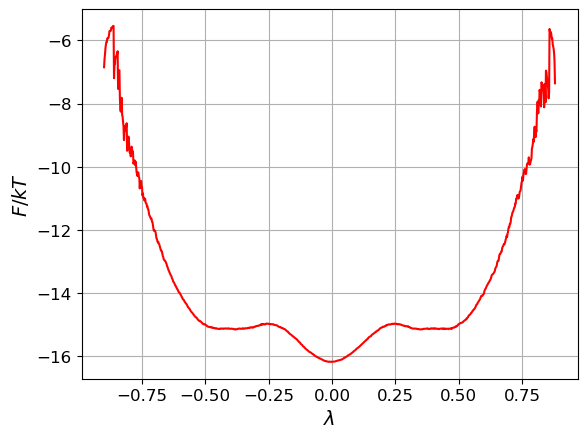

In [3]:
fig, ax = plt.subplots(1, 1)
plots.plot_fep(ax, cp.asarray(lam), xlabel='$\\lambda$')
plt.show()

## 4. Trajectory Indices

Single trajectory (`i_traj = 1` for all frames).

In [4]:
i_traj = np.ones_like(lam)          # trajectory index (1 = single trajectory)
t_traj = np.arange(len(lam))        # frame index

## 5. Train Committor (Non-Parametric), Several Seeds

`CommittorNE` rather than the equilibrium `Committor`: time reversal flips the velocity, so the reversible estimator does not apply to q(λ, v). The CVs are λ and the recorded velocity v; each iteration draws one of them.

The fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). Each fit runs in chunks of `CHUNK` iterations; after every chunk the metrics, FEPs + Z_q and observed-vs-predicted plots and the (λ, v) map are saved to `figures/langevin_seeds/seed<s>/it<N>_*.png`, and the error against the brute-force reference q(x, v) is printed. `fit_transform` continues from the current RC on every call, so the chunks form one continuous run.

`lazy_basis=True` evaluates the basis in fused GPU kernels: about 4× faster here, same result. It is used instead of fewer frames: the statistical error of the comparison grows from 0.012 per bin at 6M frames to 0.020 at 2M.

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `SEEDS` | 0, 1, 2 | Random seeds |
| `MAX_ITER` | 30000 | Iterations per seed |
| `CHUNK` | 5000 | Iterations between saved plots |
| `envelope_scale` | 0.001 | RC envelope width |
| `gamma` | 0.1 | Regularization (scales the step; does not change the fixed point) |
| `ny` | 6 | Polynomial degree |

#=1000, xent=0.398689, mse=0.14007, sdzq=144.553, dzq=607.589, dr2=9168.43, auc=0.869178, |dx|=0.180349, time=38.0323
#=2000, xent=0.397907, mse=0.139791, sdzq=121.784, dzq=549.484, dr2=9224.64, auc=0.86978, |dx|=0.00689379, time=75.9817
#=3000, xent=0.397583, mse=0.139654, sdzq=107.32, dzq=493.08, dr2=9286.08, auc=0.870178, |dx|=0.00402393, time=114.043
#=4000, xent=0.397384, mse=0.139586, sdzq=99.2322, dzq=469.592, dr2=9305.68, auc=0.870263, |dx|=0.00331068, time=152.139
#=5000, xent=0.397282, mse=0.139546, sdzq=95.7885, dzq=456.158, dr2=9332.55, auc=0.870308, |dx|=0.00317533, time=190.258


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3312484/567715062.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 2, 5000 iterations: RMS(fit - exact) per frame 0.0424, plots in figures/langevin_seeds/seed2
#=6000, xent=0.397182, mse=0.139506, sdzq=94.2553, dzq=448.247, dr2=9334.31, auc=0.870422, |dx|=0.00229248, time=37.9091
#=7000, xent=0.397106, mse=0.139474, sdzq=94.6724, dzq=449.137, dr2=9322.72, auc=0.870537, |dx|=0.00208394, time=75.9634
#=8000, xent=0.397102, mse=0.139474, sdzq=91.1921, dzq=438.898, dr2=9332.95, auc=0.870515, |dx|=0.00150969, time=114.014
#=9000, xent=0.397101, mse=0.139476, sdzq=93.7812, dzq=448.156, dr2=9343.09, auc=0.870497, |dx|=0.000987853, time=152.149
#=10000, xent=0.397093, mse=0.139475, sdzq=93.1302, dzq=448.487, dr2=9343.84, auc=0.870498, |dx|=0.00125455, time=190.337


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3312484/567715062.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 2, 10000 iterations: RMS(fit - exact) per frame 0.0414, plots in figures/langevin_seeds/seed2
#=11000, xent=0.39706, mse=0.139461, sdzq=91.2919, dzq=441.535, dr2=9345.84, auc=0.870521, |dx|=0.000965345, time=18.9921
#=12000, xent=0.397017, mse=0.139443, sdzq=93.213, dzq=447.759, dr2=9338.87, auc=0.870561, |dx|=0.00176602, time=37.4601
#=13000, xent=0.396993, mse=0.139435, sdzq=93.8318, dzq=450.484, dr2=9343.39, auc=0.870594, |dx|=0.000743278, time=55.9442
#=14000, xent=0.396959, mse=0.13942, sdzq=93.8165, dzq=447.934, dr2=9341.95, auc=0.870645, |dx|=0.000819899, time=74.4197
#=15000, xent=0.396965, mse=0.139421, sdzq=94.4729, dzq=450.312, dr2=9340.68, auc=0.870647, |dx|=0.000600895, time=92.9078


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3312484/567715062.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


... (3 outputs left out)

/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3312484/567715062.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 3, 10000 iterations: RMS(fit - exact) per frame 0.0408, plots in figures/langevin_seeds/seed3
#=11000, xent=0.396971, mse=0.139427, sdzq=101.637, dzq=487.141, dr2=9302.24, auc=0.870564, |dx|=0.00292636, time=18.4557
#=12000, xent=0.396971, mse=0.139428, sdzq=103.311, dzq=496.801, dr2=9295.47, auc=0.870556, |dx|=0.000875798, time=36.9415
#=13000, xent=0.396994, mse=0.13944, sdzq=103.127, dzq=497.295, dr2=9301.53, auc=0.870513, |dx|=0.00109192, time=55.4273
#=14000, xent=0.396995, mse=0.139441, sdzq=101.187, dzq=490.405, dr2=9304.92, auc=0.870506, |dx|=0.000833312, time=73.8991
#=15000, xent=0.397001, mse=0.139444, sdzq=100.729, dzq=489.838, dr2=9304.03, auc=0.870495, |dx|=0.000650386, time=92.3838


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3312484/567715062.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 3, 15000 iterations: RMS(fit - exact) per frame 0.0412, plots in figures/langevin_seeds/seed3


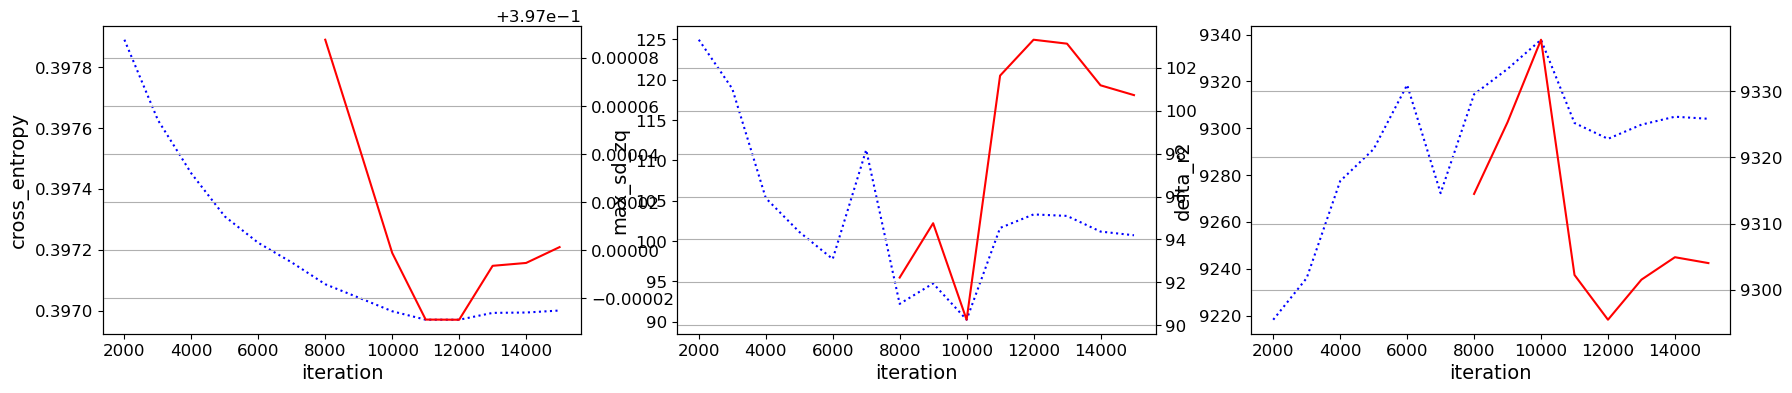

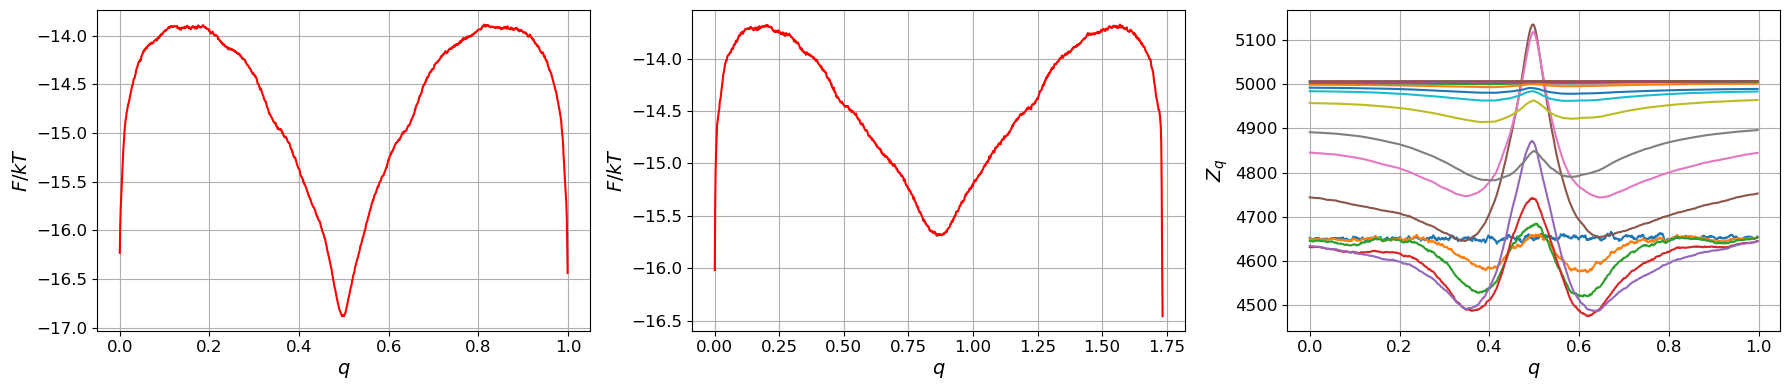

/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/conda_envs/RL/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


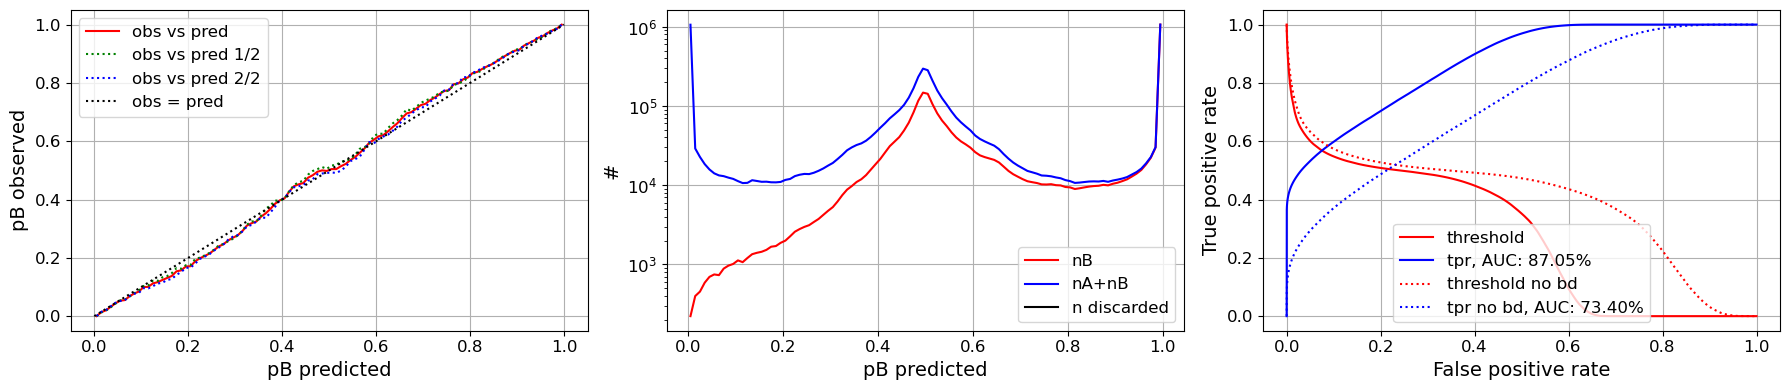

In [5]:
import os
from scipy.interpolate import RegularGridInterpolator

SEEDS = [2, 3]
MAX_ITER = 15000
CHUNK = 5000
OUT = 'figures/langevin_seeds'

optimalrcs.envelope_scale = 0.01
gamma = 0.1                        # regularization strength
Y = cp.asarray(np.c_[lam, v])      # CVs: lambda and the recorded velocity

# brute-force reference q(x, v), for the progress printout
ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l, edges_v = np.linspace(lambda_a, lambda_b, 71), np.linspace(-3, 3, 61)
n_lv = np.histogram2d(lam, v, [edges_l, edges_v])[0]

def save_plots(q, folder, tag):
    # the library's plot methods call plt.show(); keep the figures open to save them instead
    show, plt.show = plt.show, (lambda *a, **k: None)
    try:
        q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
        plt.gcf().savefig(f'{folder}/{tag}_metrics.png', dpi=100); plt.close('all')
        q.plots_feps(delta_t_sim=dt)
        plt.gcf().savefig(f'{folder}/{tag}_feps.png', dpi=100); plt.close('all')
        q.plots_obs_pred()
        plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')
        r = cp.asnumpy(q.r_traj)
        s = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)[0]
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T,
                           cmap='coolwarm', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$\\lambda$', ylabel='$v$', title=tag)
        fig.savefig(f'{folder}/{tag}_q_lambda_v.png', dpi=100); plt.close('all')
    finally:
        plt.show = show
    return r

results = {}
for seed in SEEDS:
    folder = f'{OUT}/seed{seed}'
    os.makedirs(folder, exist_ok=True)
    np.random.seed(seed); cp.random.seed(seed)
    q = optimalrcs.CommittorNE(
        boundary0=lam <= lambda_a,     # state A
        boundary1=lam >= lambda_b,     # state B
        i_traj=i_traj,
        t_traj=t_traj,
    )
    for done in range(CHUNK, MAX_ITER + 1, CHUNK):
        q.fit_transform(
            lambda: Y[:, np.random.randint(2)],
            gamma=gamma,
            ny=6,
            max_iter=CHUNK,
            print_step=1000,
            save_min_delta_zq=False,
            lazy_basis=True,
        )
        r = save_plots(q, folder, f'it{done}')
        rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        print(f'seed {seed}, {done} iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
    results[seed] = r

# Diagnostics of the last seed
q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
plt.show()
q.plots_feps(delta_t_sim=dt)
q.plots_obs_pred()

## 6. Committor in the (λ, v) Plane

Mean q per (λ, v) bin, using the true velocity from the MD. If the history captured the velocity, q depends on v and not only on λ: particles moving towards B have higher q.

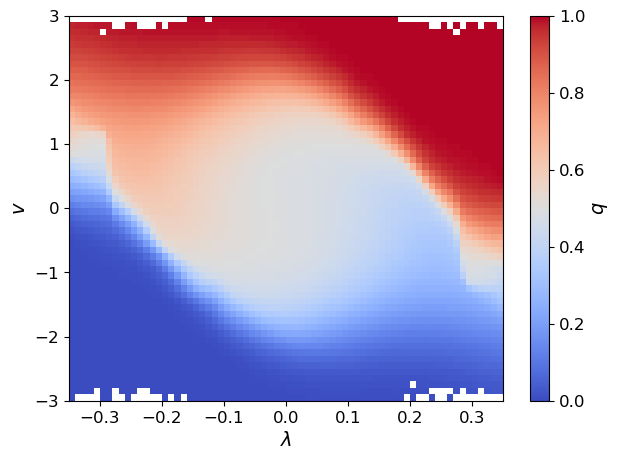

In [8]:
r = cp.asnumpy(q.r_traj)
edges_l = np.linspace(lambda_a, lambda_b, 71)
edges_v = np.linspace(-3, 3, 61)
n, _, _ = np.histogram2d(lam, v, [edges_l, edges_v])
s, _, _ = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)
q_lv = np.where(n > 20, s / np.maximum(n, 1), np.nan)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
im = ax.pcolormesh(edges_l, edges_v, q_lv.T, cmap='coolwarm', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='$q$')
ax.set(xlabel='$\\lambda$', ylabel='$v$')
plt.show()

## 7. Save Results

Uncomment to save the raw committor trajectory to disk.

In [9]:
np.save('q_traj_langevin_env0.001g0.2.npy', cp.asnumpy(q.r_traj))